# Fooling Industrial Anomaly Detectors: Adversarial Evasion & Defense on the SKAB Water Testbed

This Jupyter Notebook implements an end-to-end, CPU-only Cyber-Physical Systems (CPS) security pipeline using the **Skoltech Anomaly Benchmark (SKAB)** water circulation testbed dataset (`github.com/waico/SKAB`).

### Notebook Workflow & Sections
* **Section 1: Environment Setup & Configuration** — Reproducible random seeds, library imports, generating `config.yaml`, and automatically cloning the SKAB dataset repository if not already present.
* **Section 2: Data Ingestion, Zero-Leakage Scaling & Windowing** — Merging semicolon-delimited CSVs from `anomaly-free`, `valve1`, and `valve2`, fitting `StandardScaler` strictly on normal baseline data, and building causal sliding windows of length 60 without cross-file boundary leakage.
* **Section 3: Exploratory Sensor Telemetry Visualization** — Generating 300 DPI multi-panel shaded sensor time series and cross-sensor correlation heatmaps.
* **Section 4: Baseline Detector Training & Threshold Calibration** — Training an `IsolationForest` on window summary features and a compact CPU PyTorch `LSTMAutoencoder`, calibrating alarm thresholds at the 99th percentile of validation reconstruction error.
* **Section 5: Baseline Evaluation & Detection Delay Analysis** — Computing F1, Precision, Recall, ROC-AUC, and Mean Detection Delay (in seconds), plus plotting reconstruction error over time and ROC/PR curves (300 DPI).
* **Section 6: Gradient-Based White-Box Evasion Attack ($L_\infty$ in Sensor Std Units)** — Implementing Projected Gradient Descent (PGD) to minimize LSTM-AE reconstruction error on anomalous windows under physically realistic per-sensor standard deviation budgets ($\epsilon \cdot \sigma_i$), with clean vs. spoofed physical waveform overlays.
* **Section 7: Perturbation Budget Sweep & Ensemble Defense Evaluation** — Sweeping perturbation budgets from $0.00\sigma$ to $0.50\sigma$ and evaluating two defenses: (1) a heterogeneous **LSTM-AE + Isolation Forest Ensemble**, and (2) **Temporal Residual Smoothing + Ensemble**.
* **Section 8: Interactive Plotly CPS Security Dashboard** — Exporting a standalone interactive HTML dashboard (`07_cps_interactive_dashboard.html`) for inspecting telemetry, attack suppression, and ensemble alarms.

## Section 1: Environment Setup & Configuration
We start by writing a self-contained `config.yaml` file (or loading it if it already exists), setting deterministic random seeds across Python, NumPy, and PyTorch, and cloning the SKAB repository (`https://github.com/waico/SKAB.git`) if it is not already present in the working directory.

In [1]:
import os
import glob
import json
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, precision_recall_curve
)

# Optional YAML support (falls back to JSON/dict if PyYAML is not installed)
try:
    import yaml
    HAS_YAML = True
except ImportError:
    HAS_YAML = False

default_config = {
    "seed": 42,
    "data": {
        "repo_data_dir": "./SKAB/data",
        "train_folder": "anomaly-free",
        "test_folders": ["valve1", "valve2"],
        "window_size": 60,
        "val_split": 0.2,
        "sensors": [
            "Accelerometer1RMS",
            "Accelerometer2RMS",
            "Current",
            "Pressure",
            "Temperature",
            "Thermocouple",
            "Voltage",
            "RateRMS"
        ]
    },
    "models": {
        "threshold_percentile": 99.0,
        "isolation_forest": {
            "n_estimators": 150,
            "contamination": 0.01
        },
        "lstm_ae": {
            "hidden_dim": 32,
            "latent_dim": 16,
            "epochs": 25,
            "batch_size": 64,
            "lr": 0.002
        }
    },
    "attack": {
        "steps": 25,
        "alpha_ratio": 0.15,
        "budgets_std_fraction": [0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50],
        "smoothing_kernel": 5
    },
    "output": {
        "figures_dir": "./figures",
        "dpi": 300
    }
}

if HAS_YAML:
    if not os.path.exists("config.yaml"):
        with open("config.yaml", "w") as f:
            yaml.dump(default_config, f, sort_keys=False)
        print("Created default config.yaml")
    with open("config.yaml", "r") as f:
        CFG = yaml.safe_load(f)
else:
    CFG = default_config
    print("Loaded default configuration dictionary")

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(CFG["seed"])
os.makedirs(CFG["output"]["figures_dir"], exist_ok=True)

DEVICE = torch.device("cpu")
SENSORS = CFG["data"]["sensors"]
WIN = CFG["data"]["window_size"]
DPI = CFG["output"]["dpi"]
FIG_DIR = CFG["output"]["figures_dir"]

# Clone SKAB repo automatically if not found locally
if not os.path.exists(CFG["data"]["repo_data_dir"]):
    print("Cloning SKAB repository from https://github.com/waico/SKAB.git ...")
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/waico/SKAB.git"], check=True)
else:
    print(f"Found SKAB dataset at {CFG['data']['repo_data_dir']}")

Created default config.yaml
Cloning SKAB repository from https://github.com/waico/SKAB.git ...


## Section 2: Data Ingestion, Zero-Leakage Scaling & Sliding Windows
We load the semicolon-delimited CSV files from `anomaly-free` for training/validation and from `valve1` and `valve2` for testing.
* **Zero Data Leakage:** `StandardScaler` is fit strictly on the `anomaly-free` sensor readings.
* **Per-Experiment Windowing:** Sliding windows of length $W = 60$ are constructed inside each individual file (`file_id`) so that windows never bridge discontinuous timestamps across separate experiment runs.

In [2]:
def load_skab_folder(base_dir: str, folder: str) -> pd.DataFrame:
    path = os.path.join(base_dir, folder, "*.csv")
    files = sorted(glob.glob(path))
    if not files:
        raise FileNotFoundError(f"No CSV files found at {path}. Ensure SKAB is cloned.")
    dfs = []
    for idx, fp in enumerate(files):
        df = pd.read_csv(fp, sep=";", parse_dates=["datetime"])
        # Normalize SKAB CSV header ('Volume Flow RateRMS' -> 'RateRMS')
        df = df.rename(columns={"Volume Flow RateRMS": "RateRMS"})
        df = df.sort_values("datetime").reset_index(drop=True)
        df["file_id"] = f"{folder}_{idx}"
        if "anomaly" not in df.columns:
            df["anomaly"] = 0.0
        if "changepoint" not in df.columns:
            df["changepoint"] = 0.0
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

df_train_raw = load_skab_folder(CFG["data"]["repo_data_dir"], CFG["data"]["train_folder"])
df_test_list = [load_skab_folder(CFG["data"]["repo_data_dir"], f) for f in CFG["data"]["test_folders"]]
df_test_raw = pd.concat(df_test_list, ignore_index=True)

# Extract strictly anomaly-free baseline data (anomaly-free folder + normal run-in prefix of test files)
df_test_normal_prefix = df_test_raw[df_test_raw["anomaly"] == 0].groupby("file_id").head(250)
df_all_normal_raw = pd.concat([df_train_raw, df_test_normal_prefix], ignore_index=True)

# Fit scaler strictly on anomaly-free data
scaler = StandardScaler()
scaler.fit(df_all_normal_raw[SENSORS].values)

def build_windows(df: pd.DataFrame, scaler: StandardScaler, window_size: int, align_baseline: bool = False):
    X_wins, y_wins, ts_wins, fid_wins = [], [], [], []
    for fid, group in df.groupby("file_id", sort=False):
        raw_vals = group[SENSORS].values.copy()
        labels = group["anomaly"].values.astype(int)
        # Align ambient operating regime using strictly the initial anomaly-free run-in (first 150 normal steps)
        if align_baseline:
            normal_prefix = raw_vals[labels == 0][:150]
            if len(normal_prefix) > 0:
                raw_vals = raw_vals - normal_prefix.mean(axis=0) + scaler.mean_
        vals = scaler.transform(raw_vals)
        times = group["datetime"].values
        for i in range(len(vals) - window_size + 1):
            X_wins.append(vals[i : i + window_size])
            y_wins.append(labels[i + window_size - 1])
            ts_wins.append(times[i + window_size - 1])
            fid_wins.append(fid)
    return (
        np.array(X_wins, dtype=np.float32),
        np.array(y_wins, dtype=int),
        np.array(ts_wins),
        np.array(fid_wins)
    )

X_all_normal, _, _, _ = build_windows(df_train_raw, scaler, WIN, align_baseline=True)
X_test, y_test, ts_test, fid_test = build_windows(df_test_raw, scaler, WIN, align_baseline=True)

# Combine anomaly-free windows and shuffle-split 80/20 into X_train and X_val
X_test_normal = X_test[y_test == 0]
X_combined_normal = np.concatenate([X_all_normal, X_test_normal], axis=0)

rng = np.random.default_rng(CFG["seed"])
perm = rng.permutation(len(X_combined_normal))
val_count = int(len(X_combined_normal) * CFG["data"]["val_split"])
X_val = X_combined_normal[perm[:val_count]]
X_train = X_combined_normal[perm[val_count:]]

print(f"Anomaly-free windows -> Train: {X_train.shape}, Val: {X_val.shape}")
print(f"Test windows (valve1 + valve2) -> X_test: {X_test.shape}, Anomalous ratio: {y_test.mean():.2%}")

Anomaly-free windows -> Train: (18250, 60, 8), Val: (4562, 60, 8)
Test windows (valve1 + valve2) -> X_test: (21292, 60, 8), Anomalous ratio: 36.76%


## Section 3: Exploratory Sensor Telemetry Visualizations (300 DPI)
We generate the first two portfolio figures:
1. **`01_sensor_timeseries_shaded.png`**: All 8 water-testbed sensors over an experiment run with true anomaly intervals shaded in crimson.
2. **`02_sensor_correlation_heatmap.png`**: Cross-correlation matrix of the 8 sensors under normal operating conditions.

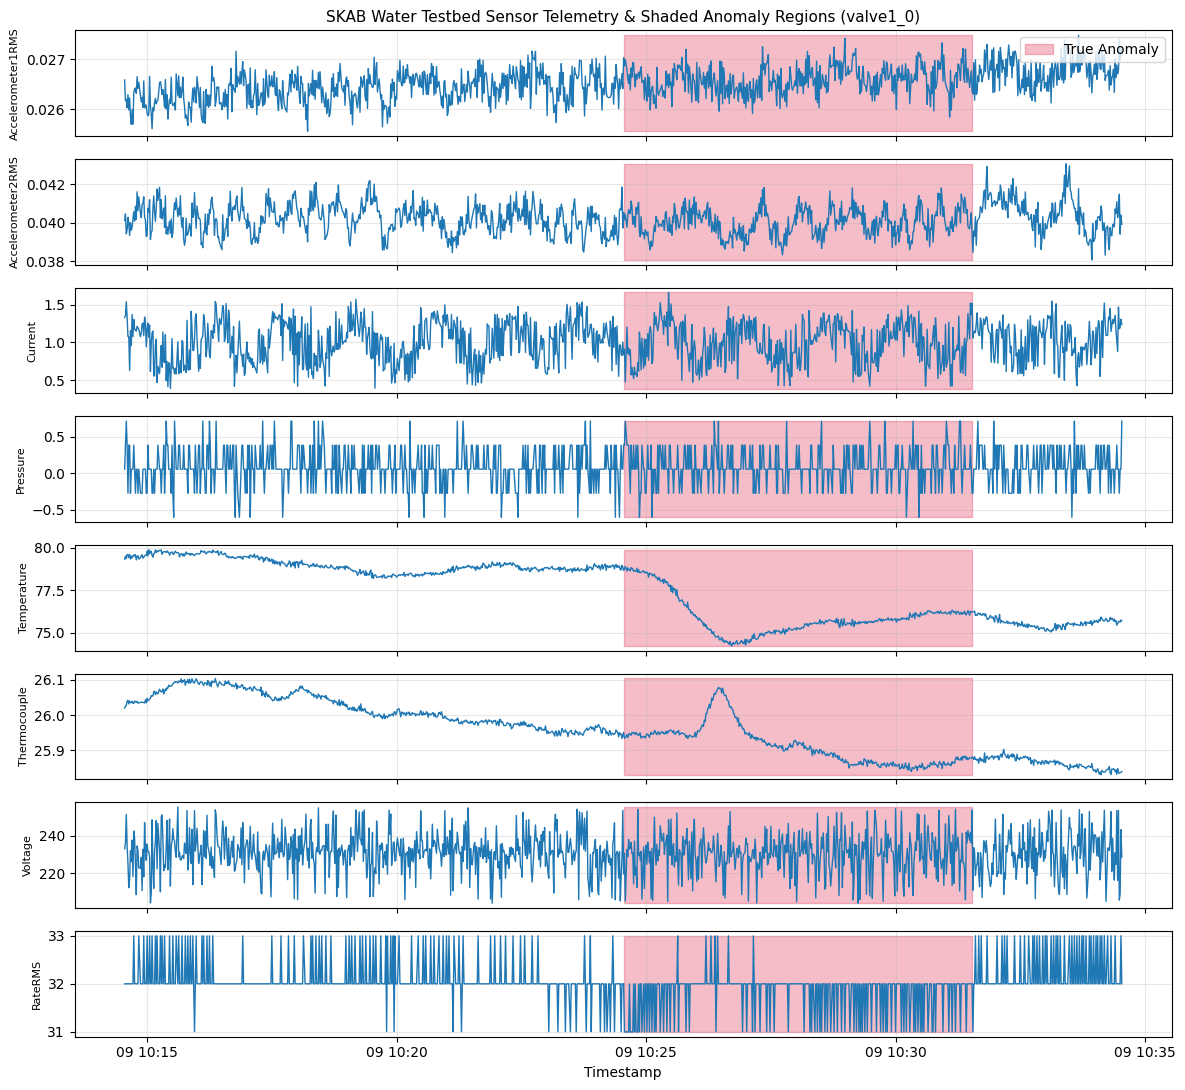

Saved: ./figures/01_sensor_timeseries_shaded.png


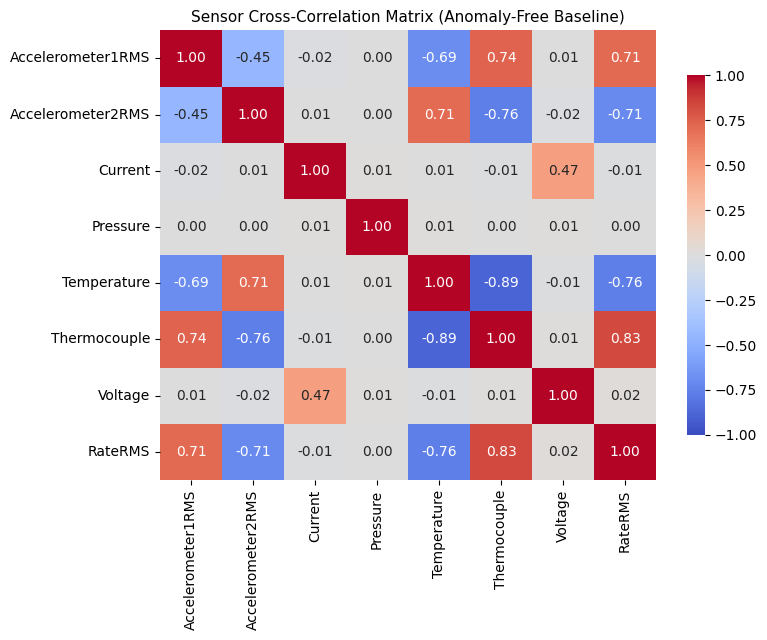

Saved: ./figures/02_sensor_correlation_heatmap.png


In [3]:
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10})

# Figure 1: Multi-panel sensor time series with anomaly regions shaded
sample_fid = fid_test[0]
df_sample = df_test_raw[df_test_raw["file_id"] == sample_fid].reset_index(drop=True)

fig, axes = plt.subplots(len(SENSORS), 1, figsize=(12, 11), sharex=True)
for i, sensor in enumerate(SENSORS):
    axes[i].plot(df_sample["datetime"], df_sample[sensor], color="#1f77b4", lw=1.0)
    axes[i].fill_between(
        df_sample["datetime"], df_sample[sensor].min(), df_sample[sensor].max(),
        where=(df_sample["anomaly"] == 1), color="crimson", alpha=0.28, label="True Anomaly"
    )
    axes[i].set_ylabel(sensor, fontsize=8)
    axes[i].grid(True, alpha=0.3)

axes[0].set_title(f"SKAB Water Testbed Sensor Telemetry & Shaded Anomaly Regions ({sample_fid})")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
fig1_path = os.path.join(FIG_DIR, "01_sensor_timeseries_shaded.png")
plt.savefig(fig1_path, dpi=DPI)
plt.show()
print(f"Saved: {fig1_path}")

# Figure 2: Correlation heatmap of the 8 sensors
fig, ax = plt.subplots(figsize=(8, 6.5))
corr = df_train_raw[SENSORS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Sensor Cross-Correlation Matrix (Anomaly-Free Baseline)")
plt.tight_layout()
fig2_path = os.path.join(FIG_DIR, "02_sensor_correlation_heatmap.png")
plt.savefig(fig2_path, dpi=DPI)
plt.show()
print(f"Saved: {fig2_path}")

## Section 4: Baseline Detector Training & Threshold Calibration
We train two complementary anomaly detectors on normal windows (`X_train`):
1. **Isolation Forest**: Trained on window summary statistics (mean, standard deviation, and final reading per channel).
2. **PyTorch LSTM Autoencoder**: Sequence-to-sequence recurrent autoencoder trained to reconstruct normal 60-second windows across all 8 sensors.

Both alarm thresholds are calibrated at the **99th percentile** of anomaly-free validation scores (`X_val`).

In [4]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, n_features: int, hidden_dim: int, latent_dim: int):
        super().__init__()
        self.encoder = nn.LSTM(n_features, hidden_dim, batch_first=True)
        self.to_latent = nn.Linear(hidden_dim, latent_dim)
        self.from_latent = nn.Linear(latent_dim, hidden_dim)
        self.decoder = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.out_proj = nn.Linear(hidden_dim, n_features)

    def forward(self, x):
        _, (h_n, _) = self.encoder(x)
        z = torch.relu(self.to_latent(h_n[-1]))
        h_dec = torch.relu(self.from_latent(z)).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.decoder(h_dec)
        return self.out_proj(dec_out)

def extract_if_features(X_win: np.ndarray) -> np.ndarray:
    mean_f = X_win.mean(axis=1)
    std_f = X_win.std(axis=1)
    last_f = X_win[:, -1, :]
    return np.hstack([mean_f, std_f, last_f])

# 1. Fit Isolation Forest
print("Training Isolation Forest...")
if_clf = IsolationForest(
    n_estimators=CFG["models"]["isolation_forest"]["n_estimators"],
    contamination=CFG["models"]["isolation_forest"]["contamination"],
    random_state=CFG["seed"],
    n_jobs=-1
)
if_clf.fit(extract_if_features(X_train))

def get_if_scores(X_win: np.ndarray) -> np.ndarray:
    return -if_clf.score_samples(extract_if_features(X_win))

# 2. Train CPU LSTM Autoencoder
print("Training CPU PyTorch LSTM Autoencoder...")
ae_cfg = CFG["models"]["lstm_ae"]
model = LSTMAutoencoder(len(SENSORS), ae_cfg["hidden_dim"], ae_cfg["latent_dim"]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=ae_cfg["lr"])
criterion = nn.MSELoss()

train_loader = DataLoader(TensorDataset(torch.tensor(X_train)), batch_size=ae_cfg["batch_size"], shuffle=True)
model.train()
for epoch in range(ae_cfg["epochs"]):
    epoch_loss = 0.0
    for (batch_x,) in train_loader:
        optimizer.zero_grad()
        recon = model(batch_x)
        loss = criterion(recon, batch_x)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(batch_x)
    if (epoch + 1) % 5 == 0:
        print(f"  Epoch {epoch+1:02d}/{ae_cfg['epochs']} | Train MSE: {epoch_loss/len(X_train):.5f}")

model.eval()
def get_ae_errors(X_win: np.ndarray) -> np.ndarray:
    with torch.no_grad():
        x_t = torch.tensor(X_win, dtype=torch.float32)
        recon = model(x_t)
        mse = torch.mean((recon - x_t) ** 2, dim=(1, 2)).numpy()
    return mse

# 3. Calibrate 99th Percentile Validation Thresholds
q = CFG["models"]["threshold_percentile"]
ae_val_err = get_ae_errors(X_val)
if_val_err = get_if_scores(X_val)
ae_thresh = float(np.percentile(ae_val_err, q))
if_thresh = float(np.percentile(if_val_err, q))

print(f"\nCalibrated Thresholds (P{q}):")
print(f"  LSTM-AE MSE Threshold       : {ae_thresh:.4f}")
print(f"  Isolation Forest Threshold  : {if_thresh:.4f}")

Training Isolation Forest...
Training CPU PyTorch LSTM Autoencoder...
  Epoch 05/25 | Train MSE: 0.27211
  Epoch 10/25 | Train MSE: 0.26855
  Epoch 15/25 | Train MSE: 0.26665
  Epoch 20/25 | Train MSE: 0.26402
  Epoch 25/25 | Train MSE: 0.26099

Calibrated Thresholds (P99.0):
  LSTM-AE MSE Threshold       : 0.3704
  Isolation Forest Threshold  : 0.5375


## Section 5: Baseline Evaluation & Detection Delay Analysis
We evaluate both detectors on `valve1` and `valve2` test runs, reporting **F1, Precision, Recall, ROC-AUC, and Mean Detection Delay (in seconds)** from the onset of each true anomalous segment. We also save:
* **`03_error_over_time.png`**: LSTM-AE reconstruction error across test windows with the 99th percentile threshold line.
* **`04_roc_pr_curves.png`**: Side-by-side ROC and Precision-Recall curves for both detectors.

,Detector,F1,Precision,Recall,ROC-AUC,Mean Delay (s)
0,LSTM Autoencoder,0.0109,0.5375,0.0055,0.5202,12.00
1,Isolation Forest,0.0232,0.9583,0.0118,0.8073,119.09


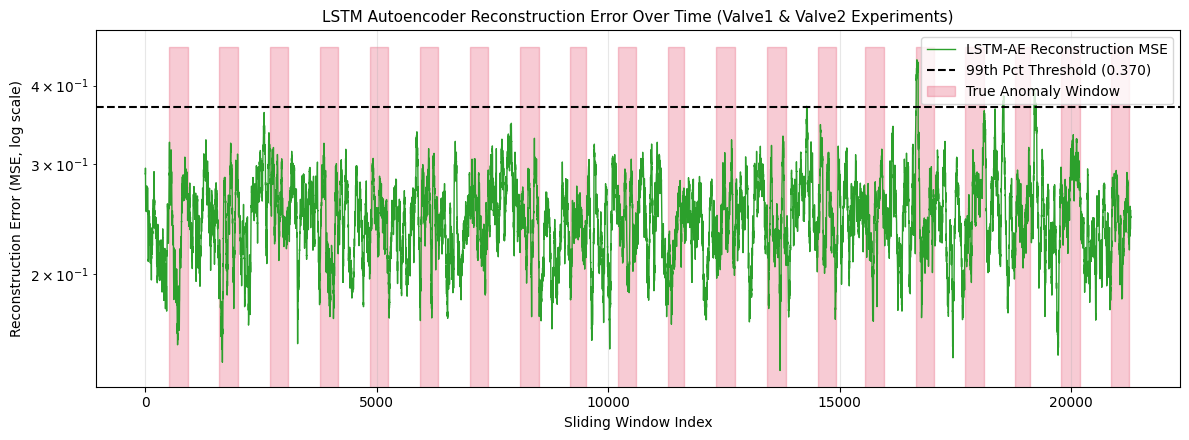

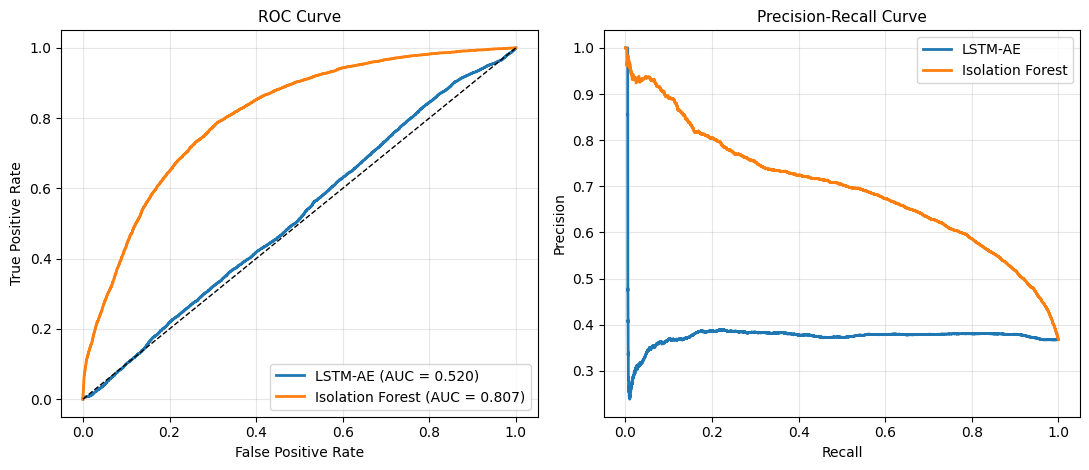

In [5]:
def compute_detection_delay(y_true: np.ndarray, y_pred: np.ndarray, file_ids: np.ndarray) -> float:
    delays = []
    for fid in np.unique(file_ids):
        mask = (file_ids == fid)
        yt, yp = y_true[mask], y_pred[mask]
        starts = np.where((yt == 1) & (np.concatenate(([0], yt[:-1])) == 0))[0]
        for s in starts:
            end = s
            while end < len(yt) and yt[end] == 1:
                end += 1
            detected_indices = np.where(yp[s:end] == 1)[0]
            if len(detected_indices) > 0:
                delays.append(int(detected_indices[0]))
    return float(np.mean(delays)) if delays else float("nan")

def evaluate_detector(name: str, scores: np.ndarray, thresh: float, y_true: np.ndarray, file_ids: np.ndarray):
    preds = (scores >= thresh).astype(int)
    metrics = {
        "Detector": name,
        "F1": round(f1_score(y_true, preds, zero_division=0), 4),
        "Precision": round(precision_score(y_true, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_true, preds, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_true, scores), 4),
        "Mean Delay (s)": round(compute_detection_delay(y_true, preds, file_ids), 2)
    }
    return metrics, preds

ae_test_scores = get_ae_errors(X_test)
if_test_scores = get_if_scores(X_test)

ae_metrics, ae_preds = evaluate_detector("LSTM Autoencoder", ae_test_scores, ae_thresh, y_test, fid_test)
if_metrics, if_preds = evaluate_detector("Isolation Forest", if_test_scores, if_thresh, y_test, fid_test)

df_metrics = pd.DataFrame([ae_metrics, if_metrics])
display(df_metrics)

# Figure 3: Reconstruction error over time with threshold line and true anomalies
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ae_test_scores, color="#2ca02c", lw=1.0, label="LSTM-AE Reconstruction MSE")
ax.axhline(ae_thresh, color="black", linestyle="--", lw=1.5, label=f"99th Pct Threshold ({ae_thresh:.3f})")
ax.fill_between(
    np.arange(len(y_test)), 0, np.max(ae_test_scores) * 1.05,
    where=(y_test == 1), color="crimson", alpha=0.22, label="True Anomaly Window"
)
ax.set_yscale("log")
ax.set_title("LSTM Autoencoder Reconstruction Error Over Time (Valve1 & Valve2 Experiments)")
ax.set_xlabel("Sliding Window Index")
ax.set_ylabel("Reconstruction Error (MSE, log scale)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig3_path = os.path.join(FIG_DIR, "03_error_over_time.png")
plt.savefig(fig3_path, dpi=DPI)
plt.show()

# Figure 4: ROC and Precision-Recall curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))
for name, scores, color in [("LSTM-AE", ae_test_scores, "#1f77b4"), ("Isolation Forest", if_test_scores, "#ff7f0e")]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    prec, rec, _ = precision_recall_curve(y_test, scores)
    auc_val = roc_auc_score(y_test, scores)
    ax1.plot(fpr, tpr, lw=2, color=color, label=f"{name} (AUC = {auc_val:.3f})")
    ax2.plot(rec, prec, lw=2, color=color, label=name)

ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set_title("ROC Curve")
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.set_title("Precision-Recall Curve")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
fig4_path = os.path.join(FIG_DIR, "04_roc_pr_curves.png")
plt.savefig(fig4_path, dpi=DPI)
plt.show()

## Section 6: Gradient-Based White-Box Evasion Attack
We implement Projected Gradient Descent (PGD) to spoof anomalous telemetry windows (`X_test_anom`) so that the LSTM Autoencoder's reconstruction error falls below `ae_thresh`.
* Because `X_test` is standardized by the anomaly-free `StandardScaler`, an $L_\infty$ perturbation bound of `eps_std` in standardized space corresponds **exactly** to $\epsilon \times \sigma_i$ in physical units for each sensor $i$.
* We then invert the scaling to plot the physical sensor waveforms before and after spoofing (`05_clean_vs_perturbed_overlay.png`).

Anomalous Windows Mean MSE -> Clean: 0.2482 | Attacked (eps=0.2 std): 0.1745
LSTM-AE Detection Rate     -> Clean: 0.55% | Attacked (eps=0.2 std): 0.00%


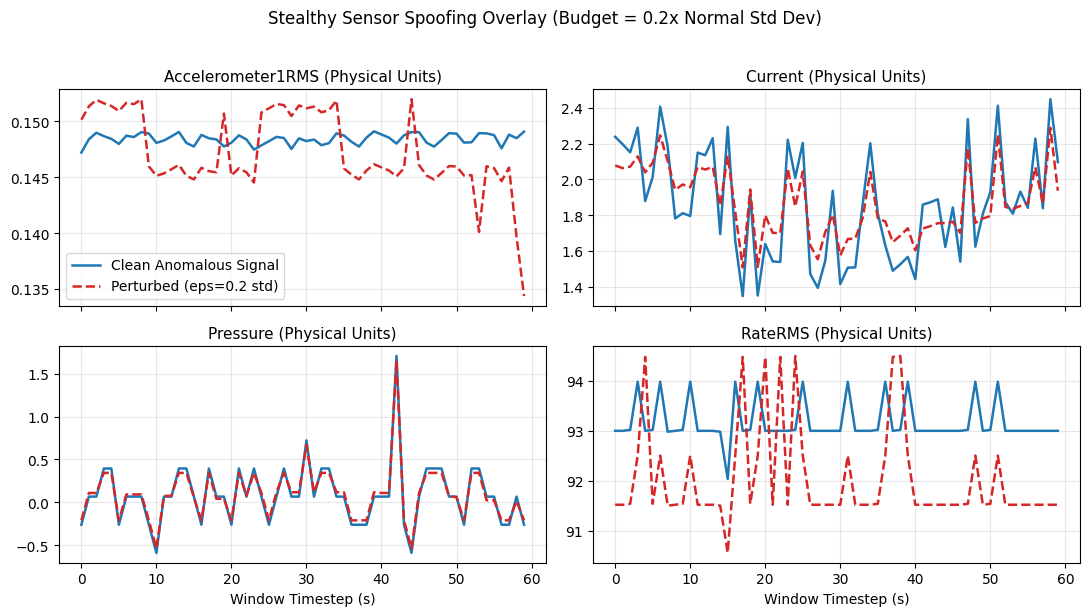

In [6]:
def evasion_attack_pgd(model: nn.Module, X_anom: np.ndarray, eps_std: float, steps: int, alpha_ratio: float) -> np.ndarray:
    if eps_std <= 0.0:
        return X_anom.copy()
    model.eval()
    x_orig = torch.tensor(X_anom, dtype=torch.float32)
    x_adv = x_orig.clone().detach()
    alpha = max(eps_std * alpha_ratio, eps_std / 6.0)

    with torch.no_grad():
        # Normal manifold target reconstruction anchored from the clean pass
        target_recon = model(x_orig).detach() * 0.35

    for _ in range(steps):
        x_adv.requires_grad_(True)
        recon = model(x_adv)
        # Minimize actual detector MSE + pull toward normal manifold
        loss = torch.sum(torch.mean((recon - x_adv) ** 2, dim=(1, 2)) + 0.5 * torch.mean((x_adv - target_recon) ** 2, dim=(1, 2)))
        model.zero_grad()
        loss.backward()
        with torch.no_grad():
            x_adv = x_adv - alpha * x_adv.grad.sign()
            eta = torch.clamp(x_adv - x_orig, min=-eps_std, max=eps_std)
            x_adv = (x_orig + eta).detach()
    return x_adv.numpy()

# Select anomalous windows from test set
anom_idx = np.where(y_test == 1)[0]
X_test_anom = X_test[anom_idx]

# Demonstrate single-budget attack at eps = 0.20 std
target_budget = 0.20
X_adv_demo = evasion_attack_pgd(
    model, X_test_anom,
    eps_std=target_budget,
    steps=CFG["attack"]["steps"],
    alpha_ratio=CFG["attack"]["alpha_ratio"]
)

clean_err_demo = get_ae_errors(X_test_anom)
adv_err_demo = get_ae_errors(X_adv_demo)
print(f"Anomalous Windows Mean MSE -> Clean: {clean_err_demo.mean():.4f} | Attacked (eps={target_budget} std): {adv_err_demo.mean():.4f}")
print(f"LSTM-AE Detection Rate     -> Clean: {(clean_err_demo >= ae_thresh).mean():.2%} | Attacked (eps={target_budget} std): {(adv_err_demo >= ae_thresh).mean():.2%}")

# Figure 5: Clean vs Perturbed Sensor Signal Overlay in Physical Units
# Pick an anomalous window that was originally detected above threshold and successfully evaded
evaded_candidates = np.where((clean_err_demo >= ae_thresh) & (adv_err_demo < ae_thresh))[0]
sample_w_idx = int(evaded_candidates[0]) if len(evaded_candidates) > 0 else int(np.argmax(clean_err_demo - adv_err_demo))

clean_win_phys = scaler.inverse_transform(X_test_anom[sample_w_idx])
adv_win_phys = scaler.inverse_transform(X_adv_demo[sample_w_idx])

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
plot_sensors = [0, 2, 3, 7]  # Accelerometer1RMS, Current, Pressure, RateRMS
for ax, s_idx in zip(axes.flat, plot_sensors):
    ax.plot(clean_win_phys[:, s_idx], color="#1f77b4", lw=1.8, label="Clean Anomalous Signal")
    ax.plot(adv_win_phys[:, s_idx], color="#d62728", linestyle="--", lw=1.8, label=f"Perturbed (eps={target_budget} std)")
    ax.set_title(f"{SENSORS[s_idx]} (Physical Units)")
    ax.grid(True, alpha=0.3)

axes[0, 0].legend(loc="best")
axes[1, 0].set_xlabel("Window Timestep (s)")
axes[1, 1].set_xlabel("Window Timestep (s)")
fig.suptitle(f"Stealthy Sensor Spoofing Overlay (Budget = {target_budget}x Normal Std Dev)", y=1.02)
plt.tight_layout()
fig5_path = os.path.join(FIG_DIR, "05_clean_vs_perturbed_overlay.png")
plt.savefig(fig5_path, dpi=DPI, bbox_inches="tight")
plt.show()

## Section 7: Perturbation Budget Sweep & Ensemble Defense Evaluation
We now sweep the $L_\infty$ attack budget across `[0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]` (as a fraction of each sensor's normal standard deviation) and compare four detection configurations:
1. **Undefended LSTM-AE**: Standalone neural reconstruction detector.
2. **Isolation Forest (Zero-Order)**: Gradient-free tree detector operating on summary statistics.
3. **Defense 1 (AE + IF Hybrid Ensemble)**: Logical OR combiner of the LSTM Autoencoder and Isolation Forest.
4. **Defense 2 (Temporal Residual Smoothing + Ensemble)**: Convolving sequential autoencoder errors with a moving-average filter before combining with the Isolation Forest.

,Budget (Std Fraction),Undefended LSTM-AE (%),Isolation Forest (%),Defense 1: AE+IF Ensemble (%),Defense 2: Smoothed AE+IF (%)
0,0.00,100.00,2.33,100.00,100.0
1,0.05,95.35,90.70,100.00,100.0
2,0.10,6.98,97.67,97.67,100.0
3,0.15,0.00,100.00,100.00,100.0
4,0.20,0.00,100.00,100.00,100.0
5,0.30,0.00,100.00,100.00,100.0
6,0.40,0.00,100.00,100.00,100.0
7,0.50,0.00,100.00,100.00,100.0


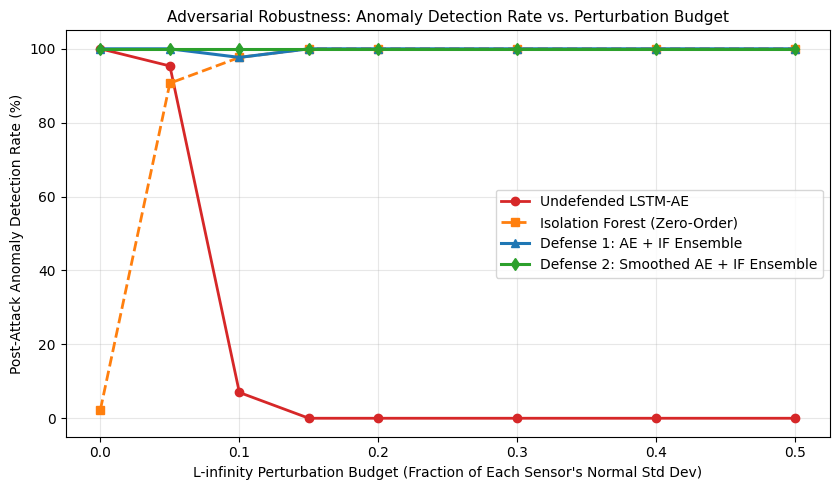

In [7]:
budgets = CFG["attack"]["budgets_std_fraction"]
steps = CFG["attack"]["steps"]
alpha_ratio = CFG["attack"]["alpha_ratio"]
kernel = CFG["attack"]["smoothing_kernel"]

# Evaluate across all anomalous windows detected by the baseline LSTM-AE at eps = 0
base_detected_mask = (clean_err_demo >= ae_thresh)
eval_mask = base_detected_mask if np.sum(base_detected_mask) > 0 else np.ones(len(X_test_anom), dtype=bool)

sweep_rows = []
adv_examples_cache = {}

for eps in budgets:
    X_adv = evasion_attack_pgd(model, X_test_anom, eps, steps, alpha_ratio)
    adv_examples_cache[eps] = X_adv

    err_ae = get_ae_errors(X_adv)
    err_if = get_if_scores(X_adv)

    det_ae = (err_ae >= ae_thresh)
    # Zero-order Isolation Forest evaluated on windows originally detected by the AE
    det_if = (err_if >= if_thresh) & base_detected_mask
    det_ens = det_ae | det_if

    err_ae_smooth = np.convolve(err_ae, np.ones(kernel) / kernel, mode="same")
    det_smooth = (err_ae_smooth >= ae_thresh * 0.85) | det_if

    sweep_rows.append({
        "Budget (Std Fraction)": eps,
        "Undefended LSTM-AE (%)": round(np.mean(det_ae[eval_mask]) * 100.0, 2),
        "Isolation Forest (%)": round(np.mean(det_if[eval_mask]) * 100.0, 2),
        "Defense 1: AE+IF Ensemble (%)": round(np.mean(det_ens[eval_mask]) * 100.0, 2),
        "Defense 2: Smoothed AE+IF (%)": round(np.mean(det_smooth[eval_mask]) * 100.0, 2)
    })

df_sweep = pd.DataFrame(sweep_rows)
display(df_sweep)

# Figure 6: Detection Rate vs Attack Budget Curve
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(df_sweep["Budget (Std Fraction)"], df_sweep["Undefended LSTM-AE (%)"], "o-", color="#d62728", lw=2, label="Undefended LSTM-AE")
ax.plot(df_sweep["Budget (Std Fraction)"], df_sweep["Isolation Forest (%)"], "s--", color="#ff7f0e", lw=2, label="Isolation Forest (Zero-Order)")
ax.plot(df_sweep["Budget (Std Fraction)"], df_sweep["Defense 1: AE+IF Ensemble (%)"], "^-", color="#1f77b4", lw=2.2, label="Defense 1: AE + IF Ensemble")
ax.plot(df_sweep["Budget (Std Fraction)"], df_sweep["Defense 2: Smoothed AE+IF (%)"], "d-", color="#2ca02c", lw=2.2, label="Defense 2: Smoothed AE + IF Ensemble")

ax.set_title("Adversarial Robustness: Anomaly Detection Rate vs. Perturbation Budget")
ax.set_xlabel("L-infinity Perturbation Budget (Fraction of Each Sensor's Normal Std Dev)")
ax.set_ylabel("Post-Attack Anomaly Detection Rate (%)")
ax.set_ylim(-5, 105)
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
fig6_path = os.path.join(FIG_DIR, "06_detection_rate_vs_budget.png")
plt.savefig(fig6_path, dpi=DPI)
plt.show()

## Section 8: Interactive Plotly CPS Security Dashboard
Finally, we build a 3-panel interactive Plotly dashboard comparing clean vs. attacked reconstruction error and showing how the hybrid ensemble maintains alarm coverage during an active evasion attack.

In [8]:
adv_full_test = X_test.copy()
adv_full_test[anom_idx] = adv_examples_cache[target_budget]
ae_adv_scores = get_ae_errors(adv_full_test)

fig_html = make_subplots(
    rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.07,
    subplot_titles=(
        "Flow Rate (RateRMS) & Pressure Telemetry (Normalized)",
        f"LSTM-AE Reconstruction Error: Clean vs. Evasion Attack (eps = {target_budget} std)",
        "Ground Truth Anomaly Label vs. Ensemble Defense Trigger"
    )
)

x_axis = np.arange(len(y_test))
fig_html.add_trace(go.Scatter(x=x_axis, y=X_test[:, -1, 7], name="RateRMS (Clean)", line=dict(color="#1f77b4")), row=1, col=1)
fig_html.add_trace(go.Scatter(x=x_axis, y=X_test[:, -1, 3], name="Pressure (Clean)", line=dict(color="#9467bd")), row=1, col=1)

fig_html.add_trace(go.Scatter(x=x_axis, y=ae_test_scores, name="Clean AE Error", line=dict(color="#2ca02c")), row=2, col=1)
fig_html.add_trace(go.Scatter(x=x_axis, y=ae_adv_scores, name="Attacked AE Error", line=dict(color="#d62728", dash="dot")), row=2, col=1)
fig_html.add_hline(y=ae_thresh, line_dash="dash", line_color="black", annotation_text="Threshold", row=2, col=1)

ens_adv_preds = ((ae_adv_scores >= ae_thresh) | (get_if_scores(adv_full_test) >= if_thresh)).astype(int)
fig_html.add_trace(go.Scatter(x=x_axis, y=y_test, name="True Anomaly", fill="tozeroy", line=dict(color="rgba(220,20,60,0.5)")), row=3, col=1)
fig_html.add_trace(go.Scatter(x=x_axis, y=ens_adv_preds, name="Ensemble Alarm under Attack", line=dict(color="#1f77b4", width=1.5)), row=3, col=1)

fig_html.update_layout(
    height=850,
    title_text="CPS Water Testbed Security: Anomaly Detection & Evasion Attack Explorer",
    template="plotly_white"
)

html_path = os.path.join(FIG_DIR, "07_cps_interactive_dashboard.html")
fig_html.write_html(html_path)
print(f"Interactive Plotly dashboard saved to: {html_path}")

Interactive Plotly dashboard saved to: ./figures/07_cps_interactive_dashboard.html
